In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pickle

with open(
    "/content/drive/MyDrive/Colab Notebooks/beth_prepared.pkl",
    "rb"
) as f:
    dati_preparati = pickle.load(f)

X_train_rel = dati_preparati["X_train_rel"]
X_validation_rel = dati_preparati["X_validation_rel"]
X_test_rel = dati_preparati["X_test_rel"]

y_train = dati_preparati["y_train"]
y_validation = dati_preparati["y_validation"]
y_test = dati_preparati["y_test"]

event_features = dati_preparati["event_features"]

print("Dati caricati.")
print("Train:", X_train_rel.shape)
print("Validation:", X_validation_rel.shape)
print("Test:", X_test_rel.shape)

Dati caricati.
Train: (128, 32)
Validation: (22, 32)
Test: (13, 32)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler_lof = StandardScaler()

# Fit SOLO sul train
Xs_train_lof = scaler_lof.fit_transform(X_train_rel)

# Validation e test solo trasformati
Xs_validation_lof = scaler_lof.transform(X_validation_rel)
Xs_test_lof = scaler_lof.transform(X_test_rel)

print("Train standardizzato:", Xs_train_lof.shape)
print("Validation standardizzato:", Xs_validation_lof.shape)
print("Test standardizzato:", Xs_test_lof.shape)

Train standardizzato: (128, 32)
Validation standardizzato: (22, 32)
Test standardizzato: (13, 32)


In [ ]:
from sklearn.neighbors import LocalOutlierFactor

lof_model = LocalOutlierFactor(
    n_neighbors=20,
    contamination="auto",
    novelty=True
)

lof_model.fit(Xs_train_lof)

print("LOF addestrato correttamente sul TRAIN standardizzato.")
print("Numero finestre train:", Xs_train_lof.shape[0])
print("Numero feature:", Xs_train_lof.shape[1])

LOF addestrato correttamente sul TRAIN standardizzato.
Numero finestre train: 128
Numero feature: 32


In [ ]:
# TRAIN:
# per i dati usati nel fit utilizziamo negative_outlier_factor_
anomaly_score_train_lof = -lof_model.negative_outlier_factor_

# VALIDATION e TEST:
# sono dati nuovi, quindi utilizziamo score_samples()
anomaly_score_validation_lof = -lof_model.score_samples(
    Xs_validation_lof
)

anomaly_score_test_lof = -lof_model.score_samples(
    Xs_test_lof
)

print("TRAIN:")
print(
    f"min={anomaly_score_train_lof.min():.6f} | "
    f"max={anomaly_score_train_lof.max():.6f}"
)

print("\nVALIDATION:")
print(
    f"min={anomaly_score_validation_lof.min():.6f} | "
    f"max={anomaly_score_validation_lof.max():.6f}"
)

print("\nTEST:")
print(
    f"min={anomaly_score_test_lof.min():.6f} | "
    f"max={anomaly_score_test_lof.max():.6f}"
)

TRAIN:
min=0.964311 | max=8.169342

VALIDATION:
min=1.006558 | max=5.188125

TEST:
min=0.977283 | max=40.848254


Qui la convenzione rimane:

score più alto → finestra più anomala.

In [ ]:
import pandas as pd

y_test_sus = y_test["sus_window"].astype(int).values
y_test_evil = y_test["evil_window"].astype(int).values

risultati_test_lof = pd.DataFrame({
    "window": range(len(anomaly_score_test_lof)),
    "anomaly_score_lof": anomaly_score_test_lof,
    "SUS_reale": y_test_sus,
    "EVIL_reale": y_test_evil
})

print(risultati_test_lof.to_string(index=False))

 window  anomaly_score_lof  SUS_reale  EVIL_reale
      0          10.930899          1           1
      1           4.010582          0           0
      2           1.030939          0           0
      3           0.977283          1           0
      4           1.006115          1           0
      5          40.848254          0           0
      6           1.290986          0           0
      7           8.415363          0           0
      8           4.186322          0           0
      9           5.896467          1           1
     10           5.808901          1           1
     11          28.545595          1           1
     12          27.671615          1           1


la finestra 5 ha lo score massimo (40.848) pur non essendo né SUS né EVIL; non è un errore del codice, perché LOF rileva anomalie rispetto alla distribuzione dei dati, non direttamente le nostre etichette.

Ora calcoliamo le AUC definitive del LOF.

In [ ]:
from sklearn.metrics import roc_auc_score

auc_sus_lof = roc_auc_score(
    y_test_sus,
    anomaly_score_test_lof
)

auc_evil_lof = roc_auc_score(
    y_test_evil,
    anomaly_score_test_lof
)

print(f"AUC SUS  - LOF: {auc_sus_lof:.3f}")
print(f"AUC EVIL - LOF: {auc_evil_lof:.3f}")

AUC SUS  - LOF: 0.548
AUC EVIL - LOF: 0.825


Ora facciamo la ROC definitiva del LOF

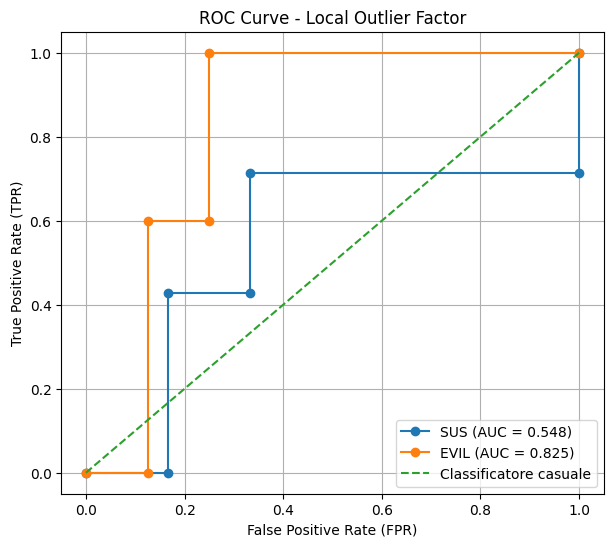

In [ ]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

# ROC SUS
fpr_sus_lof, tpr_sus_lof, _ = roc_curve(
    y_test_sus,
    anomaly_score_test_lof
)

# ROC EVIL
fpr_evil_lof, tpr_evil_lof, _ = roc_curve(
    y_test_evil,
    anomaly_score_test_lof
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr_sus_lof,
    tpr_sus_lof,
    marker="o",
    label=f"SUS (AUC = {auc_sus_lof:.3f})"
)

plt.plot(
    fpr_evil_lof,
    tpr_evil_lof,
    marker="o",
    label=f"EVIL (AUC = {auc_evil_lof:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    "--",
    label="Classificatore casuale"
)

plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("ROC Curve - Local Outlier Factor")
plt.legend()
plt.grid(True)
plt.show()

la ROC è coerente: SUS è vicino al comportamento casuale (AUC 0.548), mentre EVIL mostra una separazione decisamente migliore (AUC 0.825). Con sole 13 finestre TEST è normale che la curva sia molto “a gradini”.

In [ ]:
import numpy as np

percentili = [90, 95, 97, 99]

thresholds_lof = {
    p: np.percentile(anomaly_score_train_lof, p)
    for p in percentili
}

print("Soglie candidate LOF corrette:")

for p, threshold in thresholds_lof.items():
    print(f"{p}% -> {threshold:.6f}")

Soglie candidate LOF corrette:
90% -> 4.021868
95% -> 5.359671
97% -> 5.557790
99% -> 7.575945


Adesso dobbiamo verificare solo sulla VALIDATION quale comportamento producono per SUS. Ricordiamo che abbiamo appena 2 finestre SUS positive, quindi qualsiasi scelta sarà comunque fragile.

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np

y_val_sus = y_validation["sus_window"].astype(int).values

print("Finestre SUS reali nella VALIDATION:")
print(np.where(y_val_sus == 1)[0])
print()

for p, threshold in thresholds_lof.items():

    pred_val_sus = (
        anomaly_score_validation_lof >= threshold
    ).astype(int)

    precision = precision_score(
        y_val_sus,
        pred_val_sus,
        zero_division=0
    )

    recall = recall_score(
        y_val_sus,
        pred_val_sus,
        zero_division=0
    )

    f1 = f1_score(
        y_val_sus,
        pred_val_sus,
        zero_division=0
    )

    print(
        f"{p}% | soglia={threshold:.6f} | "
        f"Precision={precision:.3f} | "
        f"Recall={recall:.3f} | "
        f"F1={f1:.3f}"
    )

    print(
        "Finestre segnalate:",
        np.where(pred_val_sus == 1)[0]
    )
    print()

Finestre SUS reali nella VALIDATION:
[ 0 21]

90% | soglia=4.021868 | Precision=0.000 | Recall=0.000 | F1=0.000
Finestre segnalate: [ 8 10 12 16 20]

95% | soglia=5.359671 | Precision=0.000 | Recall=0.000 | F1=0.000
Finestre segnalate: []

97% | soglia=5.557790 | Precision=0.000 | Recall=0.000 | F1=0.000
Finestre segnalate: []

99% | soglia=7.575945 | Precision=0.000 | Recall=0.000 | F1=0.000
Finestre segnalate: []



per LOF non possiamo selezionare una soglia SUS sulla validation. Tutte e quattro hanno F1 = 0. In particolare, il 90% segnala cinque finestre ma nessuna delle due vere SUS; le altre non segnalano nulla.

Quindi nel risultato finale LOF avremo threshold_selection["SUS"] = None. Non scegliamo 90/95/97/99 arbitrariamente.

Ora dobbiamo fare l'analisi esplorativa sul TEST SUS con le nuove soglie. Non serve per scegliere la soglia: serve per documentare cosa succede ai quattro percentili prefissati dal TRAIN.

In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

y_test_sus = y_test["sus_window"].astype(int).values

for p, threshold in thresholds_lof.items():

    pred_test_sus = (
        anomaly_score_test_lof >= threshold
    ).astype(int)

    cm = confusion_matrix(
        y_test_sus,
        pred_test_sus
    )

    precision = precision_score(
        y_test_sus,
        pred_test_sus,
        zero_division=0
    )

    recall = recall_score(
        y_test_sus,
        pred_test_sus,
        zero_division=0
    )

    f1 = f1_score(
        y_test_sus,
        pred_test_sus,
        zero_division=0
    )

    print(f"\n--- Soglia {p}% ({threshold:.6f}) ---")
    print(
        "Finestre predette anomale:",
        np.where(pred_test_sus == 1)[0]
    )
    print("Confusion matrix:")
    print(cm)

    print(
        f"Precision={precision:.3f} | "
        f"Recall={recall:.3f} | "
        f"F1={f1:.3f}"
    )


--- Soglia 90% (4.021868) ---
Finestre predette anomale: [ 0  5  7  8  9 10 11 12]
Confusion matrix:
[[3 3]
 [2 5]]
Precision=0.625 | Recall=0.714 | F1=0.667

--- Soglia 95% (5.359671) ---
Finestre predette anomale: [ 0  5  7  9 10 11 12]
Confusion matrix:
[[4 2]
 [2 5]]
Precision=0.714 | Recall=0.714 | F1=0.714

--- Soglia 97% (5.557790) ---
Finestre predette anomale: [ 0  5  7  9 10 11 12]
Confusion matrix:
[[4 2]
 [2 5]]
Precision=0.714 | Recall=0.714 | F1=0.714

--- Soglia 99% (7.575945) ---
Finestre predette anomale: [ 0  5  7 11 12]
Confusion matrix:
[[4 2]
 [4 3]]
Precision=0.600 | Recall=0.429 | F1=0.500


I risultati mostrano che il comportamento di LOF cambia a seconda della soglia ricavata dai percentili del TRAIN. Con la soglia al 90% il modello segnala 8 finestre come anomale, ottenendo Precision = 0.625, Recall = 0.714 e F1 = 0.667. Con le soglie al 95% e 97% le predizioni coincidono e producono il miglior F1 osservato sul TEST, pari a 0.714, con Precision = 0.714 e Recall = 0.714. Con la soglia al 99%, invece, il modello diventa più restrittivo, segnala soltanto 5 finestre e il Recall scende a 0.429, con F1 = 0.500.

Questi risultati, però, non devono essere usati per selezionare la soglia operativa. La selezione deve avvenire sulla VALIDATION, e in quella partizione nessuna delle soglie candidate ha identificato correttamente le due finestre SUS reali: per tutte le soglie Precision, Recall e F1 risultano pari a 0. Di conseguenza, per LOF non viene selezionata alcuna soglia SUS. I risultati sul TEST vengono riportati esclusivamente come analisi esplorativa del comportamento delle soglie definite a priori tramite i percentili del TRAIN.

In [ ]:
y_test_evil = y_test["evil_window"].astype(int).values

for p, threshold in thresholds_lof.items():

    pred_test_evil = (
        anomaly_score_test_lof >= threshold
    ).astype(int)

    cm = confusion_matrix(
        y_test_evil,
        pred_test_evil
    )

    precision = precision_score(
        y_test_evil,
        pred_test_evil,
        zero_division=0
    )

    recall = recall_score(
        y_test_evil,
        pred_test_evil,
        zero_division=0
    )

    f1 = f1_score(
        y_test_evil,
        pred_test_evil,
        zero_division=0
    )

    print(f"\n--- Soglia {p}% ({threshold:.6f}) ---")
    print(
        "Finestre predette anomale:",
        np.where(pred_test_evil == 1)[0]
    )

    print("Confusion matrix:")
    print(cm)

    print(
        f"Precision={precision:.3f} | "
        f"Recall={recall:.3f} | "
        f"F1={f1:.3f}"
    )


--- Soglia 90% (4.021868) ---
Finestre predette anomale: [ 0  5  7  8  9 10 11 12]
Confusion matrix:
[[5 3]
 [0 5]]
Precision=0.625 | Recall=1.000 | F1=0.769

--- Soglia 95% (5.359671) ---
Finestre predette anomale: [ 0  5  7  9 10 11 12]
Confusion matrix:
[[6 2]
 [0 5]]
Precision=0.714 | Recall=1.000 | F1=0.833

--- Soglia 97% (5.557790) ---
Finestre predette anomale: [ 0  5  7  9 10 11 12]
Confusion matrix:
[[6 2]
 [0 5]]
Precision=0.714 | Recall=1.000 | F1=0.833

--- Soglia 99% (7.575945) ---
Finestre predette anomale: [ 0  5  7 11 12]
Confusion matrix:
[[6 2]
 [2 3]]
Precision=0.600 | Recall=0.600 | F1=0.600


Per la label EVIL, LOF mostra un comportamento migliore rispetto a SUS. Con le soglie al 90%, 95% e 97% il modello identifica tutte e 5 le finestre EVIL presenti nel TEST, ottenendo quindi Recall = 1.000. In particolare, le soglie al 95% e 97% producono le stesse predizioni, con Precision = 0.714 e F1 = 0.833. La soglia al 99% è invece più restrittiva: identifica soltanto 3 delle 5 finestre EVIL, facendo scendere Recall e F1 a 0.600.

Anche in questo caso, tuttavia, non è metodologicamente corretto scegliere il 95% o il 97% come soglia EVIL sulla base del loro F1 sul TEST. La VALIDATION non contiene alcuna finestra EVIL positiva e non consente quindi di effettuare una selezione della soglia basata su Precision, Recall o F1. I risultati ottenuti sul TEST devono pertanto essere interpretati esclusivamente come valutazione esplorativa delle soglie definite tramite i percentili del TRAIN.

Nel complesso, il risultato è coerente con l'AUC EVIL = 0.825: LOF riesce a ordinare relativamente bene le finestre EVIL assegnando loro score di anomalia elevati, ma genera anche falsi positivi. Ad esempio, alle soglie 95% e 97% vengono segnalate 7 finestre, delle quali 5 sono effettivamente EVIL e 2 non lo sono.

permutation-based sensitivity analysis sulla validation

In [ ]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
n_repeats = 30

# Baseline: score della VALIDATION non perturbata
baseline_scores = anomaly_score_validation_lof.copy()

sensibilita_lof = []

for j, feature in enumerate(event_features):

    variazioni = []

    for _ in range(n_repeats):

        # Copia della validation standardizzata
        X_perm = Xs_validation_lof.copy()

        # Permutiamo una sola feature
        X_perm[:, j] = rng.permutation(X_perm[:, j])

        # La validation è unseen rispetto al fit:
        # score_samples() è quindi appropriato
        perm_scores = -lof_model.score_samples(X_perm)

        # Variazione media assoluta dell'anomaly score
        variazione = np.mean(
            np.abs(perm_scores - baseline_scores)
        )

        variazioni.append(variazione)

    sensibilita_lof.append({
        "feature": feature,
        "sensitivity_mean": np.mean(variazioni),
        "sensitivity_std": np.std(variazioni)
    })

sensibilita_lof_df = pd.DataFrame(
    sensibilita_lof
).sort_values(
    "sensitivity_mean",
    ascending=False
).reset_index(drop=True)

print(sensibilita_lof_df.head(10).to_string(index=False))

              feature  sensitivity_mean  sensitivity_std
security_inode_unlink          0.568385         0.158911
   security_file_open          0.558760         0.182049
               unlink          0.550065         0.154686
                lstat          0.493666         0.146647
               access          0.459621         0.131011
               openat          0.409740         0.125307
                fstat          0.362677         0.103808
           getdents64          0.306094         0.142118
               socket          0.274586         0.101204
                 stat          0.261149         0.084221


L'analisi di sensibilità mostra che gli anomaly score prodotti da LOF sulla validation risultano maggiormente sensibili alle perturbazioni di security_inode_unlink, security_file_open e unlink, seguite da lstat, access e openat. Ciò indica che alterare la distribuzione di queste feature produce, mediamente, le variazioni più elevate negli anomaly score assegnati dal modello.

È importante sottolineare che questa analisi non rappresenta una feature importance nativa di LOF e non implica una relazione causale tra le syscall e la presenza di attività malevola. Si tratta invece di una misura post-hoc di sensibilità: per ciascuna feature, i valori vengono permutati mantenendo inalterate le altre feature e viene misurata la variazione assoluta media dello score di anomalia.

La sensitivity è stata calcolata sulla VALIDATION, non sul TRAIN. Questa scelta è particolarmente rilevante per LOF utilizzato con novelty=True: il modello viene addestrato esclusivamente sul TRAIN, mentre score_samples() viene applicato a campioni non utilizzati durante il fitting. In questo modo, lo score originale e quello ottenuto dopo la permutazione vengono calcolati con la stessa procedura.

Le deviazioni standard mostrano inoltre una variabilità non trascurabile tra le 30 permutazioni. Pertanto, soprattutto per feature con valori medi relativamente vicini, l'ordinamento non deve essere interpretato come una graduatoria rigida.

Ora facciamo il grafico delle top 10

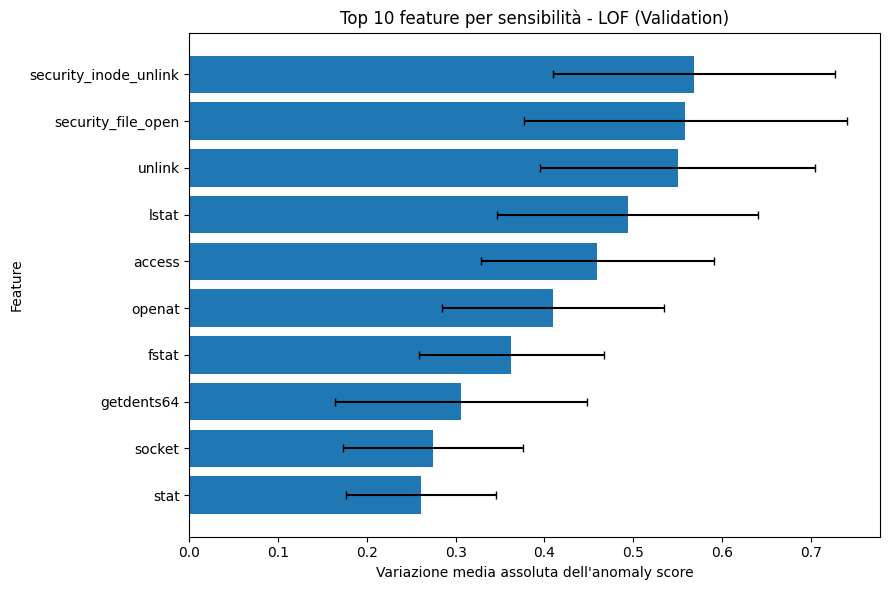

In [ ]:
import matplotlib.pyplot as plt

top10_lof = sensibilita_lof_df.head(10).sort_values(
    "sensitivity_mean",
    ascending=True
)

plt.figure(figsize=(9, 6))

plt.barh(
    top10_lof["feature"],
    top10_lof["sensitivity_mean"],
    xerr=top10_lof["sensitivity_std"],
    capsize=3
)

plt.xlabel("Variazione media assoluta dell'anomaly score")
plt.ylabel("Feature")
plt.title("Top 10 feature per sensibilità - LOF (Validation)")

plt.tight_layout()
plt.show()

Ora facciamo il profilo delle top 10 feature LOF sulle 13 finestre TEST. Usiamo X_test_rel, quindi frequenze relative originali e interpretabili, non valori standardizzati.

In [ ]:
# Nomi delle 10 feature più sensibili
top10_features_lof = (
    sensibilita_lof_df
    .head(10)["feature"]
    .tolist()
)

# Costruiamo il profilo usando le frequenze relative originali
if hasattr(X_test_rel, "loc"):
    profili_lof_test = X_test_rel[
        top10_features_lof
    ].copy()
else:
    indici_top10 = [
        event_features.index(f)
        for f in top10_features_lof
    ]

    profili_lof_test = pd.DataFrame(
        X_test_rel[:, indici_top10],
        columns=top10_features_lof
    )

# Aggiungiamo score e ground truth
profili_lof_test.insert(
    0,
    "EVIL_reale",
    y_test_evil
)

profili_lof_test.insert(
    0,
    "SUS_reale",
    y_test_sus
)

profili_lof_test.insert(
    0,
    "anomaly_score_lof",
    anomaly_score_test_lof
)

profili_lof_test.insert(
    0,
    "window",
    range(len(profili_lof_test))
)

print(profili_lof_test.to_string(index=False))

 window  anomaly_score_lof  SUS_reale  EVIL_reale  security_inode_unlink  security_file_open   unlink    lstat   access   openat    fstat  getdents64   socket     stat
      0          10.930899          1           1               0.008465            0.172584 0.004938 0.029626 0.007054 0.221961 0.113567    0.033858 0.010816 0.042323
      1           4.010582          0           0               0.000000            0.142857 0.000000 0.000000 0.000000 0.142857 0.142857    0.000000 0.142857 0.000000
      2           1.030939          0           0               0.000000            0.287435 0.000000 0.000000 0.000861 0.292599 0.029260    0.001721 0.000861 0.090361
      3           0.977283          1           0               0.000000            0.166667 0.000000 0.001449 0.004348 0.176812 0.165217    0.028986 0.037681 0.015942
      4           1.006115          1           0               0.000000            0.281199 0.000000 0.000000 0.000810 0.289303 0.037277    0.001621 0.003241 0

L'analisi delle frequenze relative delle 10 feature a cui LOF risulta maggiormente sensibile mostra che le finestre anomale non presentano necessariamente un unico profilo comune. La finestra 0, realmente SUS ed EVIL, riceve uno score elevato (10.931) e presenta valori rilevanti in diverse feature, tra cui openat, security_file_open e fstat.

Le finestre 9 e 10, anch'esse SUS ed EVIL, ottengono score rispettivamente pari a 5.896 e 5.809 e mostrano una presenza consistente di syscall quali openat, fstat e security_file_open. Al contrario, le finestre 11 e 12, entrambe SUS ed EVIL, ricevono score molto elevati (28.546 e 27.672) pur mostrando valori molto bassi o nulli per gran parte delle 10 feature globalmente più sensibili.

Questo risultato non costituisce una contraddizione: la sensitivity è una misura globale calcolata sulla validation, mentre lo score LOF di ciascuna finestra dipende dalla sua posizione locale nello spazio completo delle 32 feature rispetto ai campioni del TRAIN. Di conseguenza, le 10 feature più sensibili a livello globale non sono necessariamente quelle che spiegano lo score di ogni singola finestra.

Un caso particolarmente evidente è la finestra 5, che presenta lo score LOF più elevato dell'intero TEST (40.848) pur non essendo etichettata né SUS né EVIL e mostrando valore zero per tutte le 10 feature riportate nella tabella. Ciò suggerisce che la sua anomalia sia associata al profilo delle altre feature non incluse nella top 10 oppure, più in generale, alla combinazione complessiva delle 32 feature. Non è quindi corretto interpretare questo caso come un errore certo di LOF: le etichette SUS/EVIL e il concetto unsupervised di anomalia rispetto alla distribuzione del TRAIN non sono necessariamente equivalenti.

Nel complesso, questi risultati aiutano a interpretare la differenza tra AUC SUS (0.548) e AUC EVIL (0.825): LOF assegna score elevati a diverse finestre EVIL, ma assegna score elevati anche ad alcune finestre non etichettate come SUS/EVIL e score molto bassi ad alcune finestre SUS, come le finestre 3 e 4. Questo riduce soprattutto la capacità del modello di ordinare correttamente le finestre rispetto alla label SUS.

In [ ]:
risultati_lof = {
    # Modello e preprocessing
    "model": lof_model,
    "scaler": scaler_lof,

    # Anomaly score
    "anomaly_score_train": anomaly_score_train_lof,
    "anomaly_score_validation": anomaly_score_validation_lof,
    "anomaly_score_test": anomaly_score_test_lof,

    # AUC sul TEST
    "auc_sus": auc_sus_lof,
    "auc_evil": auc_evil_lof,

    # Soglie candidate ottenute dal TRAIN
    "thresholds_train": thresholds_lof,

    # Nessuna soglia operativa selezionabile dalla validation
    "threshold_selection": {
        "SUS": None,
        "SUS_reason": (
            "Tutte le soglie candidate 90/95/97/99 hanno F1=0 "
            "sulla validation, che contiene 2 finestre SUS positive."
        ),
        "EVIL": None,
        "EVIL_reason": (
            "La validation non contiene finestre EVIL positive; "
            "non è quindi possibile selezionare una soglia EVIL "
            "tramite metriche supervisionate."
        )
    },

    # Sensitivity post-hoc calcolata sulla VALIDATION
    "feature_sensitivity": sensibilita_lof_df,
    "sensitivity_dataset": "validation",
    "sensitivity_repeats": 30,

    # Top 10 e profili TEST
    "top10_features": top10_features_lof,
    "test_feature_profiles": profili_lof_test,

    # Parametri LOF
    "hyperparameters": {
        "n_neighbors": 20,
        "contamination": "auto",
        "novelty": True
    }
}

print("risultati_lof creato correttamente.")
print("\nChiavi salvate:")
print(list(risultati_lof.keys()))

risultati_lof creato correttamente.

Chiavi salvate:
['model', 'scaler', 'anomaly_score_train', 'anomaly_score_validation', 'anomaly_score_test', 'auc_sus', 'auc_evil', 'thresholds_train', 'threshold_selection', 'feature_sensitivity', 'sensitivity_dataset', 'sensitivity_repeats', 'top10_features', 'test_feature_profiles', 'hyperparameters']


In [ ]:
import pickle

percorso_lof = "/content/drive/MyDrive/Colab Notebooks/lof_results.pkl"

with open(percorso_lof, "wb") as f:
    pickle.dump(risultati_lof, f)

print("LOF salvato in:")
print(percorso_lof)

# Verifica immediata del file salvato
with open(percorso_lof, "rb") as f:
    verifica_lof = pickle.load(f)

print("\nFile ricaricato correttamente.")
print("Chiavi:")
print(list(verifica_lof.keys()))

print("\nAUC salvate:")
print("SUS :", verifica_lof["auc_sus"])
print("EVIL:", verifica_lof["auc_evil"])

print("\nSoglie TRAIN salvate:")
print(verifica_lof["thresholds_train"])

print("\nSelezione soglie:")
print(verifica_lof["threshold_selection"])

LOF salvato in:
/content/drive/MyDrive/Colab Notebooks/lof_results.pkl

File ricaricato correttamente.
Chiavi:
['model', 'scaler', 'anomaly_score_train', 'anomaly_score_validation', 'anomaly_score_test', 'auc_sus', 'auc_evil', 'thresholds_train', 'threshold_selection', 'feature_sensitivity', 'sensitivity_dataset', 'sensitivity_repeats', 'top10_features', 'test_feature_profiles', 'hyperparameters']

AUC salvate:
SUS : 0.5476190476190477
EVIL: 0.825

Soglie TRAIN salvate:
{90: np.float64(4.021868349597645), 95: np.float64(5.359670706563409), 97: np.float64(5.557790322520017), 99: np.float64(7.575944616576593)}

Selezione soglie:
{'SUS': None, 'SUS_reason': 'Tutte le soglie candidate 90/95/97/99 hanno F1=0 sulla validation, che contiene 2 finestre SUS positive.', 'EVIL': None, 'EVIL_reason': 'La validation non contiene finestre EVIL positive; non è quindi possibile selezionare una soglia EVIL tramite metriche supervisionate.'}
